# Verify current version of Python

In [1]:
from platform import python_version

print(python_version())

3.9.7


# Load csv files 

In [2]:
import pandas as pd 
#import numpy as np 
import json 
#import seaborn as sns 
#import matplotlib.pyplot as plt 


In [3]:
# to place r in front of the directory of the file to run the file

user_log_df = pd.read_csv(r'C:\Dataset (Advanced Programming)\23 December assessment AP\USER_LOG.csv')
activity_log_df = pd.read_csv(r'C:\Dataset (Advanced Programming)\23 December assessment AP\ACTIVITY_LOG.csv')
component_codes_df = pd.read_csv(r'C:\Dataset (Advanced Programming)\23 December assessment AP\COMPONENT_CODES.csv')
        
  

In [4]:
user_log_df


,Date,Time,User Full Name *Anonymized
0,17/11/2023 00:00,00:00:00,129
1,10/11/2023 00:00,00:00:01,26
2,10/11/2023 00:00,00:00:02,26
3,20/12/2023 00:00,00:00:02,86
4,20/12/2023 00:00,00:00:03,86
...,...,...,...
150830,20/11/2023 00:00,23:59:47,125
150831,19/12/2023 00:00,23:59:47,86
150832,12/10/2023 00:00,23:59:50,129
150833,09/11/2023 00:00,23:59:56,26


In [5]:
activity_log_df

,User Full Name *Anonymized,Component,Action,Target
0,129,Course,Viewed,Content
1,26,Quiz,Updated,Response
2,26,Quiz,Viewed,Attempt
3,86,Assignment,Viewed,Assignment
4,86,Assignment,Viewed,Submission_state
...,...,...,...,...
150830,125,Course,Viewed,Content
150831,86,System,Viewed,Content
150832,129,Course,Viewed,Course
150833,26,Quiz,Viewed,Attempt


In [6]:
component_codes_df

,Component,Code
0,Course,Cour
1,Quiz,Quiz
2,Assignment,Assign
3,System,Sys
4,Lecture,Lect
5,Study_material,Study_mat
6,Manual,Man
7,Survey,Survey
8,Folder,Fold
9,Attendence,Attend


# Translate the csv files to JSON format and save them to a file

In [7]:

json_user_log_df = user_log_df.to_json(orient='records', indent=4)

# Save to file
with open('user_log_df.json', 'w') as file:
    file.write(json_user_log_df)
    

In [8]:
json_activity_log_df = activity_log_df.to_json(orient='records', indent=4)

# Save to file
with open('activity_log_df.json', 'w') as file:
    file.write(json_activity_log_df)
    

In [9]:
json_component_codes_df = component_codes_df.to_json(orient='records', indent=4)

# Save to file
with open('component_codes_df.json', 'w') as file:
    file.write(json_component_codes_df)
    

# Process for cleaning and preparing the data set, managing inconsistencies, errors and missing values

In [10]:
with open('user_log_df.json') as file:
    data = json.load(file)

In [11]:
user_log_df = pd.json_normalize(data)
print(user_log_df.head())
user_log_df

               Date       Time  User Full Name *Anonymized
0  17/11/2023 00:00   00:00:00                         129
1  10/11/2023 00:00   00:00:01                          26
2  10/11/2023 00:00   00:00:02                          26
3  20/12/2023 00:00   00:00:02                          86
4  20/12/2023 00:00   00:00:03                          86


,Date,Time,User Full Name *Anonymized
0,17/11/2023 00:00,00:00:00,129
1,10/11/2023 00:00,00:00:01,26
2,10/11/2023 00:00,00:00:02,26
3,20/12/2023 00:00,00:00:02,86
4,20/12/2023 00:00,00:00:03,86
...,...,...,...
150830,20/11/2023 00:00,23:59:47,125
150831,19/12/2023 00:00,23:59:47,86
150832,12/10/2023 00:00,23:59:50,129
150833,09/11/2023 00:00,23:59:56,26


In [12]:
user_log_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150835 entries, 0 to 150834
Data columns (total 3 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   Date                        150835 non-null  object
 1   Time                        150835 non-null  object
 2   User Full Name *Anonymized  150835 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 3.5+ MB


In [13]:
with open('activity_log_df.json') as file:
    data = json.load(file)

In [14]:
activity_log_df = pd.json_normalize(data)
print(activity_log_df.head())
activity_log_df.head

   User Full Name *Anonymized   Component   Action            Target
0                         129      Course   Viewed           Content
1                          26        Quiz  Updated          Response
2                          26        Quiz   Viewed           Attempt
3                          86  Assignment   Viewed        Assignment
4                          86  Assignment   Viewed  Submission_state


<bound method NDFrame.head of         User Full Name *Anonymized   Component   Action            Target
0                              129      Course   Viewed           Content
1                               26        Quiz  Updated          Response
2                               26        Quiz   Viewed           Attempt
3                               86  Assignment   Viewed        Assignment
4                               86  Assignment   Viewed  Submission_state
...                            ...         ...      ...               ...
150830                         125      Course   Viewed           Content
150831                          86      System   Viewed           Content
150832                         129      Course   Viewed            Course
150833                          26        Quiz   Viewed           Attempt
150834                          26        Quiz  Updated          Response

[150835 rows x 4 columns]>

In [15]:
activity_log_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150835 entries, 0 to 150834
Data columns (total 4 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   User Full Name *Anonymized  150835 non-null  int64 
 1   Component                   150835 non-null  object
 2   Action                      150835 non-null  object
 3   Target                      150835 non-null  object
dtypes: int64(1), object(3)
memory usage: 4.6+ MB


In [16]:
with open('component_codes_df.json') as file:
    data = json.load(file)

In [17]:
component_codes_df = pd.json_normalize(data)
print(component_codes_df.head())
component_codes_df.head

    Component    Code
0      Course    Cour
1        Quiz    Quiz
2  Assignment  Assign
3      System     Sys
4     Lecture    Lect


<bound method NDFrame.head of          Component       Code
0           Course       Cour
1             Quiz       Quiz
2       Assignment     Assign
3           System        Sys
4          Lecture       Lect
5   Study_material  Study_mat
6           Manual        Man
7           Survey     Survey
8           Folder       Fold
9       Attendence     Attend
10            Page       Page
11            Test       Test
12             URL        Url
13            Book       Book
14          Source      Sourc
15   Questionnaire      Quest
16        Feedback   Feedback
17         Project       Proj>

In [18]:
component_codes_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Component  18 non-null     object
 1   Code       18 non-null     object
dtypes: object(2)
memory usage: 416.0+ bytes


In [19]:
# Check for missing values print
print(user_log_df.isnull().sum()) 


Date                          0
Time                          0
User Full Name *Anonymized    0
dtype: int64


In [20]:
print(activity_log_df.isnull().sum()) 


User Full Name *Anonymized    0
Component                     0
Action                        0
Target                        0
dtype: int64


In [21]:
print(component_codes_df.isnull().sum()) 


Component    0
Code         0
dtype: int64


In [22]:
# Drop or fill missing values 
user_log_df.dropna(inplace=True) 



In [23]:
activity_log_df.dropna(inplace=True) 


In [24]:
component_codes_df.dropna(inplace=True) 


In [25]:
#  fill missing values 
user_log_df.fillna(method='ffill', inplace=True) 


In [26]:
activity_log_df.fillna(method='ffill', inplace=True) 


In [27]:
component_codes_df.fillna(method='ffill', inplace=True)

In [28]:
# remove unnecesary components

# REMOVE: No outputs should include any data from Component: System and Folder

In [29]:
activity_log_df = activity_log_df[~activity_log_df['Component'].isin(['System', 'Folder'])]
print (activity_log_df)


        User Full Name *Anonymized       Component   Action            Target
0                              129          Course   Viewed           Content
1                               26            Quiz  Updated          Response
2                               26            Quiz   Viewed           Attempt
3                               86      Assignment   Viewed        Assignment
4                               86      Assignment   Viewed  Submission_state
...                            ...             ...      ...               ...
150829                         129  Study_material   Viewed            Folder
150830                         125          Course   Viewed           Content
150832                         129          Course   Viewed            Course
150833                          26            Quiz   Viewed           Attempt
150834                          26            Quiz  Updated          Response

[145262 rows x 4 columns]


In [30]:
# Create copies of the DataFrames 
user_log_df = user_log_df.copy() 
activity_log_df = activity_log_df.copy()

# RENAME: the column "User Full Name *Anonymized" should be renamed as User_ID both in ACTIVITY_LOG and USER_LOG CSVs

In [31]:
#change the name of the Datasets with User full name Anomyzed to User ID

user_log_df.rename(columns={'User Full Name *Anonymized': 'User_ID'}, inplace=True)
activity_log_df.rename(columns={'User Full Name *Anonymized': 'User_ID'}, inplace=True)


In [32]:
#user_log_df.rename(columns={'User Full Name *Anonymized': 'User_ID'}, inplace=True) 
#activity_log_df.rename(columns={'User Full Name *Anonymized': 'User_ID'}, inplace=True)

In [33]:
# Index the columns used for merging 
user_log_df.set_index('User_ID', inplace=True)
activity_log_df.set_index('User_ID', inplace=True) 
component_codes_df.set_index('Component', inplace=True)


In [34]:

# Optimize memory usage if possible
activity_log_df['Action'] = activity_log_df['Action'].astype('category') 
activity_log_df['Target'] = activity_log_df['Target'].astype('category') 





In [35]:
print (user_log_df)

                     Date       Time
User_ID                             
129      17/11/2023 00:00   00:00:00
26       10/11/2023 00:00   00:00:01
26       10/11/2023 00:00   00:00:02
86       20/12/2023 00:00   00:00:02
86       20/12/2023 00:00   00:00:03
...                   ...        ...
125      20/11/2023 00:00   23:59:47
86       19/12/2023 00:00   23:59:47
129      12/10/2023 00:00   23:59:50
26       09/11/2023 00:00   23:59:56
26       09/11/2023 00:00   23:59:56

[150835 rows x 2 columns]


In [36]:
print(activity_log_df)

              Component   Action            Target
User_ID                                           
129              Course   Viewed           Content
26                 Quiz  Updated          Response
26                 Quiz   Viewed           Attempt
86           Assignment   Viewed        Assignment
86           Assignment   Viewed  Submission_state
...                 ...      ...               ...
129      Study_material   Viewed            Folder
125              Course   Viewed           Content
129              Course   Viewed            Course
26                 Quiz   Viewed           Attempt
26                 Quiz  Updated          Response

[145262 rows x 3 columns]


# MERGE: Merge the suitable CSVs for analysing user interactions with each component

In [37]:
# Perform merge operations 
merged_df = activity_log_df.merge(component_codes_df, left_on='Component', right_index=True, how='left') 
merged_df = merged_df.reset_index().merge(user_log_df.reset_index(), on='User_ID', how='left')
# Check the result 

# it might take 5 minutes

print(merged_df.head())

   User_ID Component  Action   Target  Code              Date       Time
0      129    Course  Viewed  Content  Cour  17/11/2023 00:00   00:00:00
1      129    Course  Viewed  Content  Cour  16/12/2023 00:00   00:00:15
2      129    Course  Viewed  Content  Cour  17/11/2023 00:00   00:00:39
3      129    Course  Viewed  Content  Cour  17/11/2023 00:00   00:00:43
4      129    Course  Viewed  Content  Cour  17/11/2023 00:00   00:00:47


In [38]:
print(merged_df)

           User_ID Component   Action    Target  Code              Date  \
0              129    Course   Viewed   Content  Cour  17/11/2023 00:00   
1              129    Course   Viewed   Content  Cour  16/12/2023 00:00   
2              129    Course   Viewed   Content  Cour  17/11/2023 00:00   
3              129    Course   Viewed   Content  Cour  17/11/2023 00:00   
4              129    Course   Viewed   Content  Cour  17/11/2023 00:00   
...            ...       ...      ...       ...   ...               ...   
172322943       26      Quiz  Updated  Response  Quiz  09/11/2023 00:00   
172322944       26      Quiz  Updated  Response  Quiz  09/11/2023 00:00   
172322945       26      Quiz  Updated  Response  Quiz  09/11/2023 00:00   
172322946       26      Quiz  Updated  Response  Quiz  09/11/2023 00:00   
172322947       26      Quiz  Updated  Response  Quiz  09/11/2023 00:00   

                Time  
0           00:00:00  
1           00:00:15  
2           00:00:39  
3      

In [39]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 172322948 entries, 0 to 172322947
Data columns (total 7 columns):
 #   Column     Dtype   
---  ------     -----   
 0   User_ID    int64   
 1   Component  object  
 2   Action     category
 3   Target     category
 4   Code       object  
 5   Date       object  
 6   Time       object  
dtypes: category(2), int64(1), object(4)
memory usage: 8.0+ GB


# RESHAPE: Reshape the data using pivot operation.

In [40]:
# I need to chunk the data to not get memory issues
import pandas as pd

# Function to pivot a chunk of data
def pivot_chunk(chunk):
    return chunk.pivot_table(index='User_ID', columns='Component', values='Date', aggfunc='first')# cahnge this to Action or Date

# Define chunk size
chunk_size = 100000
chunks = []

# Process the DataFrame in chunks
for start in range(0, len(merged_df), chunk_size):
    chunk = merged_df.iloc[start:start + chunk_size]
    chunk_pivoted = pivot_chunk(chunk)
    chunks.append(chunk_pivoted)

# Combine the pivoted chunks
pivoted_df = pd.concat(chunks)

# Display the pivoted DataFrame (optional)
print("Pivoted DataFrame:")
print(pivoted_df.head())

# Save pivoted data to files (optional)
pivoted_df.to_csv('pivoted_merged_df.csv', index=True)
pivoted_df.to_json('pivoted_merged_df.json', orient='records', indent=4)


#it might take few minutes

Pivoted DataFrame:
Component        Assignment            Course           Lecture Manual  \
User_ID                                                                  
16                      NaN  23/11/2023 00:00               NaN    NaN   
18                      NaN               NaN  24/11/2023 00:00    NaN   
26                      NaN               NaN               NaN    NaN   
28         15/10/2023 00:00               NaN               NaN    NaN   
86         20/12/2023 00:00               NaN               NaN    NaN   

Component              Quiz Study_material Survey Attendence Page Test  URL  \
User_ID                                                                       
16                      NaN            NaN    NaN        NaN  NaN  NaN  NaN   
18                      NaN            NaN    NaN        NaN  NaN  NaN  NaN   
26         10/11/2023 00:00            NaN    NaN        NaN  NaN  NaN  NaN   
28                      NaN            NaN    NaN        NaN  NaN  

# COUNT: the interactions for each user with the Component for each month. Add this new field to the structure

In [42]:
import pandas as pd



print("Pivoted DataFrame:")
print(pivoted_df.head())

# Reset the index to ensure 'User_ID' is a column
pivoted_df.reset_index(inplace=True)

# Function to convert dates and extract year-month in chunks
def process_chunk(chunk):
    melted = chunk.melt(id_vars=['User_ID'], var_name='Component', value_name='Date').dropna(subset=['Date'])
    melted['date'] = pd.to_datetime(melted['Date'], errors='coerce')
    melted['year_month'] = melted['date'].dt.to_period('M')
    return melted

# Define chunk size
chunk_size = 100000
chunks = []

for start in range(0, len(pivoted_df), chunk_size):
    chunk = pivoted_df.iloc[start:start + chunk_size]
    processed_chunk = process_chunk(chunk)
    chunks.append(processed_chunk)

# Combine processed chunks
processed_df = pd.concat(chunks)

# Verify column names
print("Processed DataFrame after melting and date processing:")
print(processed_df.head())

# Group by User_ID, Component, and year_month, then count interactions
interaction_counts = processed_df.groupby(['User_ID', 'Component', 'year_month']).size().reset_index(name='interaction_count')
print("Interaction Counts DataFrame:")
print(interaction_counts.head())

# Function to add interaction counts back to the original DataFrame
def add_interaction_counts(chunk):
    chunk = chunk.melt(id_vars=['User_ID'], var_name='Component', value_name='Date').dropna(subset=['Date'])
    chunk['date'] = pd.to_datetime(chunk['Date'], errors='coerce')
    chunk['year_month'] = chunk['date'].dt.to_period('M')
    chunk = chunk.merge(interaction_counts, on=['User_ID', 'Component', 'year_month'], how='left')
    return chunk

# Process the DataFrame in chunks again to add interaction counts
final_chunks = []

for start in range(0, len(pivoted_df), chunk_size):
    chunk = pivoted_df.iloc[start:start + chunk_size]
    final_chunk = add_interaction_counts(chunk)
    final_chunks.append(final_chunk)

# Combine the final processed chunks
final_df = pd.concat(final_chunks)

# Display the final DataFrame (optional)
print("Final DataFrame with Interaction Counts:")
print(final_df)

# Save the final DataFrame to a file (optional)
final_df.to_csv('final_pivoted_df_with_counts.csv', index=False)
final_df.to_json('final_pivoted_df_with_counts.json', orient='records', indent=4)


Pivoted DataFrame:
Component  User_ID        Assignment            Course           Lecture  \
0               16               NaN  23/11/2023 00:00               NaN   
1               18               NaN               NaN  24/11/2023 00:00   
2               26               NaN               NaN               NaN   
3               28  15/10/2023 00:00               NaN               NaN   
4               86  20/12/2023 00:00               NaN               NaN   

Component Manual              Quiz Study_material Survey Attendence Page Test  \
0            NaN               NaN            NaN    NaN        NaN  NaN  NaN   
1            NaN               NaN            NaN    NaN        NaN  NaN  NaN   
2            NaN  10/11/2023 00:00            NaN    NaN        NaN  NaN  NaN   
3            NaN               NaN            NaN    NaN        NaN  NaN  NaN   
4            NaN               NaN            NaN    NaN        NaN  NaN  NaN   

Component  URL Book Source Questionna

# OUTPUT statistics: Produce the mean, mode and median for the components: Quiz, Lecture, Assignement, Attendance, Survey


# a. for each month


# b. for the entire 13-week academic semester

In [45]:
import pandas as pd


# Components of interest
components_of_interest = ['Quiz', 'Lecture', 'Assignment', 'Attendance', 'Survey']

# Filter data for relevant components
filtered_df = final_df[final_df['Component'].isin(components_of_interest)].copy()

# Convert 'year_month' to datetime period for grouping
filtered_df.loc[:, 'year_month'] = filtered_df['year_month'].astype(str)

# Function to calculate statistics for each month
def calculate_statistics(df):
    statistics = df.groupby(['year_month', 'Component']).agg(
        mean_interactions=('interaction_count', 'mean'),
        median_interactions=('interaction_count', 'median'),
        mode_interactions=('interaction_count', lambda x: x.mode()[0] if not x.mode().empty else None)
    ).reset_index()
    return statistics

# Calculate statistics for each month
monthly_statistics = calculate_statistics(filtered_df)

# Calculate statistics for the entire semester
semester_statistics = filtered_df.groupby('Component').agg(
    mean_interactions=('interaction_count', 'mean'),
    median_interactions=('interaction_count', 'median'),
    mode_interactions=('interaction_count', lambda x: x.mode()[0] if not x.mode().empty else None)
).reset_index()

# Display the results
print("Monthly Statistics:")
print(monthly_statistics)

print("\nSemester Statistics:")
print(semester_statistics)


Monthly Statistics:
   year_month   Component  mean_interactions  median_interactions  \
0     2023-01  Assignment          65.291391                 79.0   
1     2023-01     Lecture          14.588235                 18.0   
2     2023-01        Quiz          28.147541                 33.0   
3     2023-01      Survey           7.000000                  7.0   
4     2023-02  Assignment          41.133333                 43.0   
5     2023-02     Lecture          19.000000                 19.0   
6     2023-02        Quiz          15.315789                 17.0   
7     2023-02      Survey           3.400000                  4.0   
8     2023-03  Assignment          67.383929                 65.0   
9     2023-03     Lecture          19.680000                 26.0   
10    2023-03        Quiz          36.979381                 50.0   
11    2023-03      Survey           7.153846                  8.0   
12    2023-04  Assignment         112.872236                134.0   
13    2023-04 

# OUTPUT CORRELATION: Produce a suitable graph that displays the following information from user interactions with the following components: Assignement, Quiz, Lecture, Book, Project, and Course. Determine if there is any significant correlation betweent the 'User_ID' and 'Component'. You will need to select an appropriate visualisation to demonstrate this.

Pivot Table:
Component  Assignment  Book      Course    Lecture  Project       Quiz
User_ID                                                               
1           40.047619   1.0   54.000000  10.000000        0  58.218750
2           58.033333   2.0   60.000000  11.000000        0  44.000000
3            7.000000   0.0   13.000000   0.000000        0  15.000000
4           51.109091   3.0   52.000000   9.000000        0  32.000000
5          103.234234   4.0  152.038462  23.296296        0  59.276923


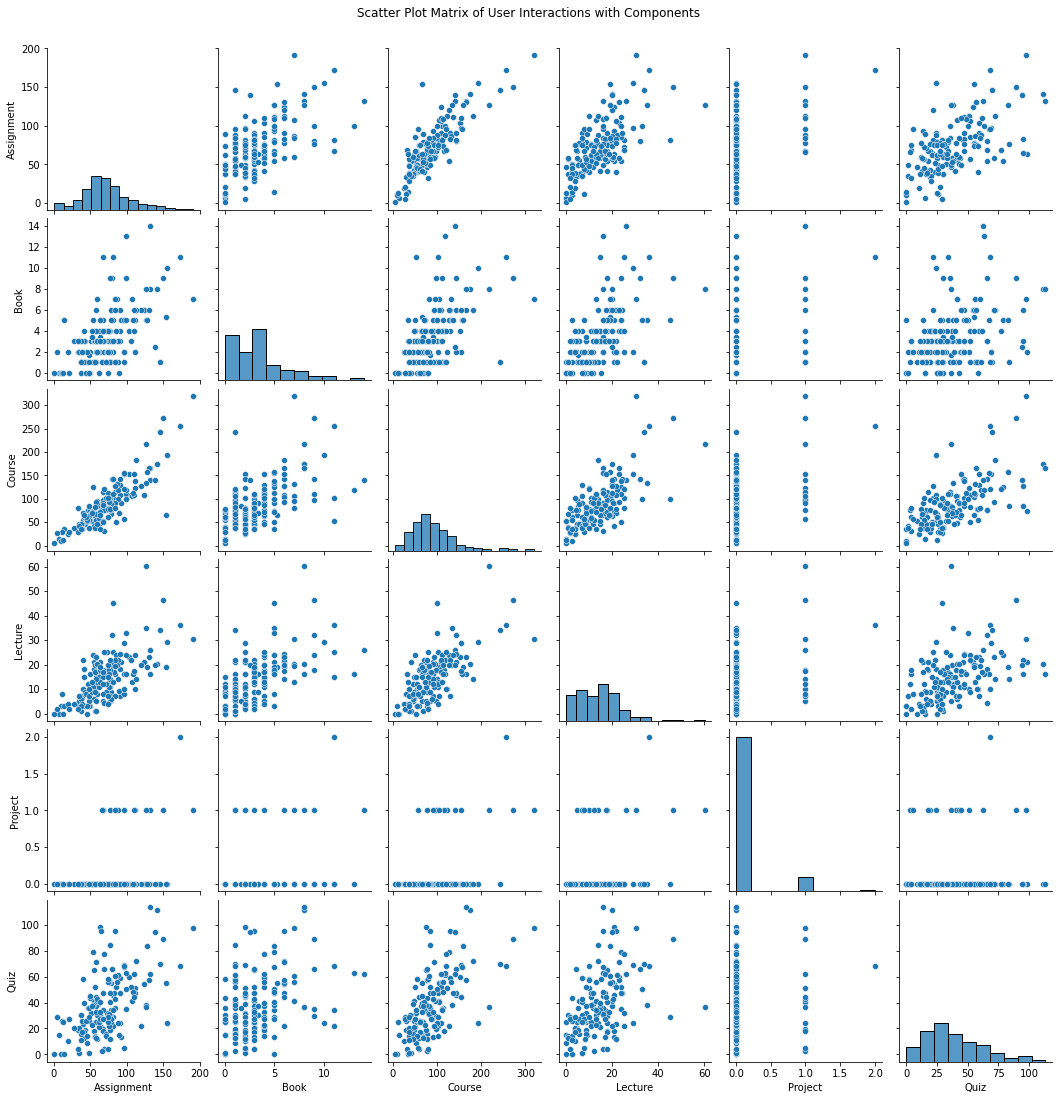

In [46]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# Filter data for relevant components
components_of_interest = ['Quiz', 'Lecture', 'Assignment', 'Book', 'Project', 'Course']
filtered_df = final_df[final_df['Component'].isin(components_of_interest)].copy()

# Convert 'year_month' to datetime period for grouping
filtered_df.loc[:, 'year_month'] = filtered_df['year_month'].astype(str)

# Create pivot table to aggregate interaction counts
pivot_table = filtered_df.pivot_table(index='User_ID', columns='Component', values='interaction_count', fill_value=0)

# Display the pivot table (optional)
print("Pivot Table:")
print(pivot_table.head())

# Create a scatter plot matrix
sns.pairplot(pivot_table)
plt.suptitle('Scatter Plot Matrix of User Interactions with Components', y=1.02)
plt.show()
